# 04 · Website export and verification

Run notebooks 01–03 first. This notebook prepares a small, versioned, **v1-only** website package from saved results. It does not rerun the statistical experiment or change the current site. The page should describe a reproduction of the first experiment in Salganik, Dodds & Watts (2006), not a full-paper replication.

Exports contain aggregate song/world statistics only. No participant IDs, registration records or demographic rows are needed for the page. Audio is optional and is not included in the web bundle: the supplied songs remain available locally, but public redistribution terms have not been established here.

In [1]:
from pathlib import Path
from itertools import combinations
import hashlib, io, json, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Works from the notebook folder, experiment folder, or repository root.
here = Path.cwd()
candidates = [here, here.parent] + list(here.glob('experiment2*'))
ROOT = next(p for p in candidates if (p / 'musiclab_data.zip').exists())
ARCHIVE = ROOT / 'musiclab_data.zip'
OUT = ROOT / 'outputs' / 'v1-reproduction'
OUT.mkdir(parents=True, exist_ok=True)
FIG = OUT / 'figures'
FIG.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 125, 'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titleweight': 'bold'})
SOCIAL = '#7959a6'
CONTROL = '#42755c'

def read_table(name):
    with zipfile.ZipFile(ARCHIVE) as z:
        return pd.read_csv(io.BytesIO(z.read(name)), header=None, comment='%', skipinitialspace=True)

def shares(counts):
    counts = np.asarray(counts, dtype=float)
    assert counts.sum() > 0
    return counts / counts.sum()

def gini(values):
    values = np.asarray(values, dtype=float)
    assert np.all(values >= 0) and values.sum() > 0
    return np.abs(values[:, None] - values[None, :]).sum() / (2 * len(values) * values.sum())

def save_figure(fig, name):
    fig.savefig(FIG / (name+'.png'), dpi=180, bbox_inches='tight')
    fig.savefig(FIG / (name+'.svg'), bbox_inches='tight')
    plt.show()

metadata = pd.read_csv(ROOT / 'data/song_metadata.csv', dtype={'song_id':str})
totals = read_table('downloads_v1_lexorder.txt')
song_ids = totals[0].astype(str).tolist()
assert metadata.song_id.tolist() == song_ids


In [2]:
WEB=ROOT/'web-assets';WEB.mkdir(exist_ok=True)
results=json.loads((OUT/'results.json').read_text());sensitivity=json.loads((OUT/'sensitivity.json').read_text())
audit=json.loads((OUT/'audit.json').read_text())
assert results['version']==1 and results['data_sha256']==audit['source_sha256']==hashlib.sha256(ARCHIVE.read_bytes()).hexdigest()
worlds=pd.read_csv(OUT/'world_summary.csv');descriptives=pd.read_csv(OUT/'audit_worlds.csv')
songs=pd.read_csv(OUT/'song_summary.csv',dtype={'song_id':str})
sw=pd.read_csv(OUT/'song_worlds.csv',dtype={'song_id':str})
splits=pd.read_csv(OUT/'control_splits.csv');pairs=pd.read_csv(OUT/'social_world_pairs.csv')
robust=pd.read_csv(OUT/'robustness_metrics.csv')
assert len(worlds)==9 and len(songs)==48 and len(sw)==432 and len(splits)==1000 and len(pairs)==28
world_records=[]
for row in worlds.to_dict('records'):
    world=int(row['world']);block=sw[sw.world==world].set_index('song_id').loc[song_ids]
    assert int(block.downloads.sum())==int(row['downloads'])
    np.testing.assert_allclose(block.share,block.downloads/block.downloads.sum())
    np.testing.assert_array_equal(block['rank'],block.downloads.rank(method='min',ascending=False))
    np.testing.assert_allclose(row['gini'],gini(block.downloads))
    record={k:(int(v) if k in ['world','participants','downloads','zero_download_participants'] else v) for k,v in row.items()}
    record.update({'counts':block.downloads.astype(int).tolist(),'shares':block.share.tolist(),'ranks':block['rank'].astype(int).tolist(),
                   'listens':int(descriptives.loc[descriptives.world==world,'listens'].iloc[0])})
    world_records.append(record)
example=songs.sort_values(['rank_span','song_id'],ascending=[False,True]).iloc[0]
summary_payload={
 'schema_version':1,'experiment':'musiclab-v1','title':'Would the same song become a hit in eight worlds?',
 'participants':7149,'song_count':48,'social_world_count':8,'independent_world_id':9,
 'assignment_probabilities':{'independent':0.2,'each_social_world':0.1},
 'sources':[
  {'label':'Original paper','url':'https://doi.org/10.1126/science.1121066'},
  {'label':'Paper and supplement','url':'https://www.princeton.edu/~mjs3/salganik_dodds_watts06_full.pdf'},
  {'label':'Data archive','url':'https://doi.org/10.34770/y56c-ym90'},
  {'label':'Author project page','url':'https://www.princeton.edu/~mjs3/musiclab.shtml'}],
 'metrics':results,'sensitivity':sensitivity,'audit':audit,
 'song_ids':song_ids,'songs':songs.to_dict('records'),'worlds':world_records,
 'independent_splits':{'gini':splits.gini.tolist(),'unpredictability':splits.unpredictability.tolist()},
 'social_pairs':pairs.to_dict('records'),'robustness':robust.to_dict('records'),
 'example':{'song_id':str(example.song_id),'selection':'largest v1 social rank span; song_id breaks any tie; illustrative selection, not a separate test'},
 'units':{'share':'fraction 0–1','unpredictability':'mean absolute share difference; multiply by 100 for percentage points',
          'gini':'uncorrected Gini; maximum 47/48 for 48 songs','rank':'competition rank, 1 + number strictly above'},
 'replication_status':{'inequality_direction':'reproduced','unpredictability_direction':'reproduced',
                       'inequality_reported_below_0_01':'not reproduced','unpredictability_reported_below_0_01':'reproduced',
                       'exact_original_seed_and_rank_ties':'unknown','excluded_raw_records':'not available'},
}
(WEB/'v1.json').write_text(json.dumps(summary_payload,separators=(',',':'),allow_nan=False)+'\n')
history=json.loads((OUT/'daily_history.json').read_text())
for item,world in zip(history['worlds'],world_records):
    assert item['world']==world['world'] and len(item['counts'])==len(history['dates'])
    x=np.array(item['counts']);assert x.shape[1]==48 and (x[0]==0).all() and (np.diff(x,axis=0)>=0).all()
    assert x[-1].tolist()==world['counts']
(WEB/'history.json').write_text(json.dumps(history,separators=(',',':'),allow_nan=False)+'\n')
# Export representative, genuinely random control partitions for an optional replay.
# Aggregates only: do not export which participants were selected.
control=read_table('dynamics_downloads_w9_v1.txt').iloc[:,2:].to_numpy(dtype=int)
rng=np.random.default_rng(20261125);demo=[]
for b in range(12):
    order=rng.permutation(len(control));a,c=np.array_split(order,[len(control)//2])
    ca,cc=control[a].sum(0),control[c].sum(0)
    np.testing.assert_allclose(gini(ca),splits.iloc[b].gini)
    demo.append({'split':b+1,'sizes':[len(a),len(c)],'counts_a':ca.tolist(),'counts_b':cc.tolist(),
                 'gini_a':gini(ca),'u':float(np.abs(shares(ca)-shares(cc)).mean())})
(WEB/'split_examples.json').write_text(json.dumps({'schema_version':1,'selection':'first 12 splits, seed 20261125','splits':demo},separators=(',',':'))+'\n')
print('Exported v1.json, history.json and 12 fixed illustrative splits.')


Exported v1.json, history.json and 12 fixed illustrative splits.


## Static fallback figures for accessible, inspectable results
Create a direct Figure 1A-style comparison and a Figure 2A-style mean comparison. No error bars are added: the observed world range and split distribution are not confidence intervals for a causal effect. For the interactive page, prefer plotting every world and the control-split distribution rather than only two mean bars.

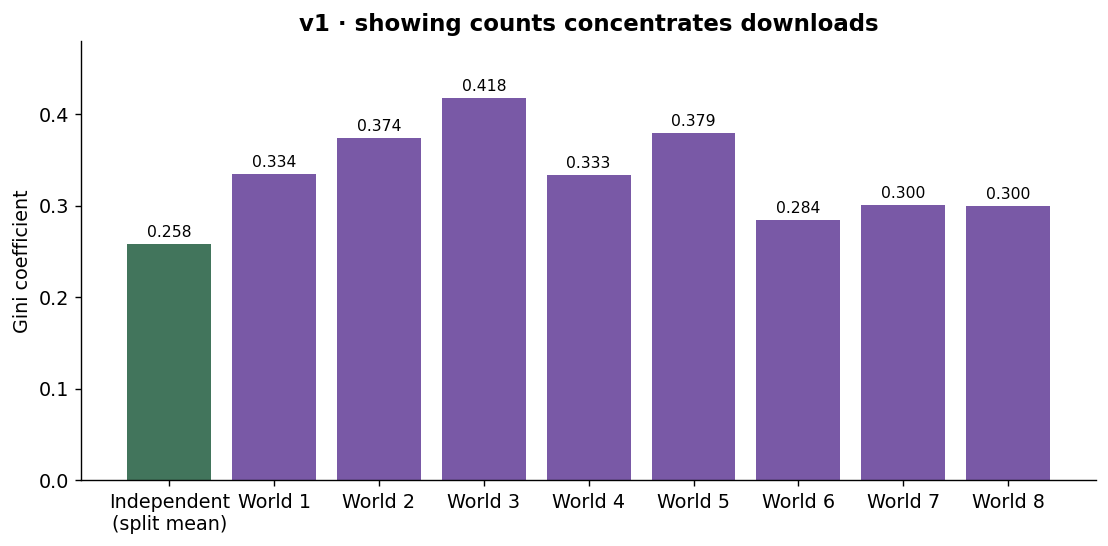

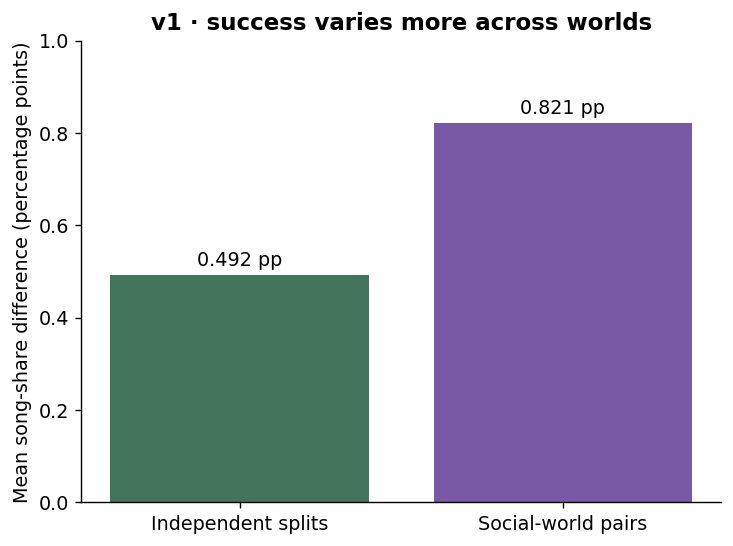

In [3]:
fig,ax=plt.subplots(figsize=(9,4.5))
values=[results['independent_gini_mean']]+worlds.loc[worlds.world<=8,'gini'].tolist()
labels=['Independent\n(split mean)']+[f'World {w}' for w in range(1,9)]
ax.bar(range(9),values,color=[CONTROL]+[SOCIAL]*8)
ax.set(xticks=range(9),xticklabels=labels,ylabel='Gini coefficient',title='v1 · showing counts concentrates downloads',ylim=(0,.48))
for i,v in enumerate(values):ax.text(i,v+.008,f'{v:.3f}',ha='center',fontsize=9)
fig.tight_layout();save_figure(fig,'01_inequality')
fig,ax=plt.subplots(figsize=(6,4.5))
values=[results['independent_u_mean']*100,results['social_u_mean']*100]
ax.bar([0,1],values,color=[CONTROL,SOCIAL]);ax.set(xticks=[0,1],xticklabels=['Independent splits','Social-world pairs'],ylabel='Mean song-share difference (percentage points)',title='v1 · success varies more across worlds',ylim=(0,1))
for i,v in enumerate(values):ax.text(i,v+.02,f'{v:.3f} pp',ha='center')
fig.tight_layout();save_figure(fig,'02_unpredictability')
# Downloadable aggregate table with readable song metadata.
sw.merge(metadata,on='song_id',validate='many_to_one').to_csv(WEB/'song_worlds.csv',index=False)


In [4]:
import shutil,platform
(WEB/'figures').mkdir(exist_ok=True)
for f in sorted(FIG.glob('*')):
    if f.suffix in ['.png','.svg']:shutil.copyfile(f,WEB/'figures'/f.name)
shutil.copyfile(OUT/'v1_comparisons.png',WEB/'figures/v1_comparisons.png')
# JSON serialization disallows NaN/Infinity. Inspect payload keys recursively for accidental raw fields.
def walk_keys(obj):
    if isinstance(obj,dict):
        for k,v in obj.items():yield k;yield from walk_keys(v)
    elif isinstance(obj,list):
        for v in obj:yield from walk_keys(v)
for f in WEB.glob('*.json'):
    if f.name=='manifest.json':continue
    payload=json.loads(f.read_text())
    assert not {'user_id','participant_id','zip_code','country','demographics'}.intersection(walk_keys(payload))
manifest={'schema_version':1,'experiment':'musiclab-v1','python_version':platform.python_version(),
          'numpy_version':np.__version__,'pandas_version':pd.__version__,
          'source_archive_sha256':audit['source_sha256'],
          'notebook_order':['01_design_and_data_audit.ipynb','02_main_outcomes.ipynb','03_song_outcomes_and_history.ipynb','04_website_export.ipynb'],
          'assets':[{ 'path':str(f.relative_to(WEB)),'bytes':f.stat().st_size,'sha256':hashlib.sha256(f.read_bytes()).hexdigest()}
                    for f in sorted(WEB.rglob('*')) if f.is_file() and f.name!='manifest.json']}
(WEB/'manifest.json').write_text(json.dumps(manifest,indent=2)+'\n')
print('Validated all website vectors, ranks, histories, source hash and JSON values.')
print(f"{len(manifest['assets'])} assets; {sum(x['bytes'] for x in manifest['assets']):,} bytes including fallback figures.")


Validated all website vectors, ranks, histories, source hash and JSON values.
17 assets; 1,511,698 bytes including fallback figures.
